# Data Cleaning & Quality Control ABIDE I (sMRI + Fenotipik)

Notebook ini membersihkan `master_dataset.csv` (hasil notebook 03) dan menyaring subjek berdasarkan kualitas citra sMRI. Hasilnya menjadi input tahap **Preprocessing**.

Prinsip yang dipakai sama dengan notebook 01–03:
- **Non-destruktif**: `df_raw` tidak pernah diubah. File input dan citra `.nii.gz` tidak disentuh.
- **Dapat diaudit**: setiap subjek yang dibuang, ditandai, atau nilainya diubah dicatat ke `cleaning_log.csv` beserta alasannya.
- **Bebas leakage**: instrumen diagnostik (ADOS, ADI-R, SRS, SCQ, AQ, DSM_IV_TR, Vineland, WISC) tidak dipakai sebagai fitur. Imputasi **tidak** dilakukan di sini. Imputasi dilakukan saat preprocessing dan di-*fit* hanya pada data latih.

| Tahap | Isi |
|---|---|
| 1 | Persiapan, log retensi, normalisasi path citra menjadi relatif (`smri_path`) |
| 2 | Cleaning fenotipik: `-9999`/karakter aneh → NaN, spasi, `*_TEST_TYPE`, handedness, cek rentang & konsistensi, encoding, `FIQ_missing` |
| 3 | Seleksi kolom (buang kolom leakage, metadata fMRI, kolom dengan missing > 50%) |
| 4 | QC citra sMRI: flag otomatis + rating QC resmi PCP, lalu drop subjek yang gagal QC |
| 5 | Kelengkapan data esensial, kriteria inklusi, dan keseimbangan kelas per site |
| 6 | Verifikasi (retensi, sebaran kelas per site, `assert`) dan export |

**Output** (`dataset/cleaned_dataset/`): `cleaned_master_dataset.csv`, `cleaning_log.csv`, `smri_qc.csv`, `data_dictionary.csv`.

## 1. Setup dan konfigurasi

Semua path diturunkan dari `PROJECT_ROOT`. Jika proyek dipindah (misalnya ke Google Drive di Colab), cukup ubah `PROJECT_ROOT`.

File rating QC PCP (`Phenotypic_V1_0b_preprocessed1.csv`) dibaca dari `dataset/fenotipik/`. Jika file belum ada dan `ALLOW_PCP_DOWNLOAD=True`, notebook mengunduhnya dari bucket publik FCP-INDI (S3).

In [26]:
from pathlib import Path
import re
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nibabel as nib
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

# Cukup ubah PROJECT_ROOT bila folder proyek dipindah.
PROJECT_ROOT = Path(r"C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR")
DATASET_DIR = PROJECT_ROOT / "dataset"
MASTER_PATH = DATASET_DIR / "merge_dataset" / "master_dataset.csv"
PHENOTYPIC_PATH = DATASET_DIR / "fenotipik" / "Phenotypic_V1_0b.csv"
SMRI_DIR = DATASET_DIR / "all_anat_T1w"
PCP_QC_PATH = DATASET_DIR / "fenotipik" / "Phenotypic_V1_0b_preprocessed1.csv"
PCP_QC_URL = ("https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/"
              "Phenotypic_V1_0b_preprocessed1.csv")

OUTPUT_DIR = DATASET_DIR / "cleaned_dataset"
CLEANED_PATH = OUTPUT_DIR / "cleaned_master_dataset.csv"
LOG_PATH = OUTPUT_DIR / "cleaning_log.csv"
QC_PATH = OUTPUT_DIR / "smri_qc.csv"
DICTIONARY_PATH = OUTPUT_DIR / "data_dictionary.csv"

### Parameter cleaning & QC

Semua keputusan yang bisa diperdebatkan dikumpulkan di sini supaya mudah diubah dan dilaporkan di bab metodologi.

- **`PCP_FAIL_RULE`** menentukan kapan rating PCP dianggap *fail*:
  - `"raw_quality"` (default): rater 3 = fail, **atau** rater 2 = fail dengan catatan masalah citra mentah (motion, noise, half head, artefak). Kegagalan rater 2 yang hanya bertuliskan *"skull-striping fail"* adalah kegagalan **pipeline PCP**, bukan kualitas citra mentah. Subjek tersebut hanya ditandai `REVIEW`, karena preprocessing di tugas akhir ini memakai pipeline sendiri.
  - `"any_fail"`: salah satu rater fail (paling konservatif).
  - `"consensus"`: kedua rater fail (paling longgar).
- **Flag otomatis** dibagi dua jenis. *Hard flag* (file hilang, gagal dibaca, bukan 3D, volume kosong, voxel non-finite, ID tidak cocok) selalu men-drop subjek. *Soft flag* (FOV < 150 mm, anisotropi > 1,5, voxel > 1,5 mm, `sform_code=0`, intensitas jenuh/negatif) hanya menandai `REVIEW`. Alasannya, soft flag mencerminkan **protokol akuisisi per site**. Contohnya, seluruh 100 citra USM anisotropik. Men-drop berdasarkan soft flag berarti menghapus satu site, bukan citra yang buruk. Soft flag tertentu bisa tetap dijadikan alasan drop lewat `DROP_ON_SOFT_FLAGS`.

In [27]:
SPECIAL_MISSING_VALUES = [-9999, -9999.0, "-9999", "-9999.0"]
# String yang hanya berisi tanda baca/spasi (mis. "`") dianggap bukan nilai.
STRAY_VALUE_PATTERN = r"^[\s`'\"\-\.\?,;:_]*$"

AGE_VALID_RANGE = (5, 70)
FIQ_VALID_RANGE = (40, 160)
INCLUDE_AGE_RANGE = None          # contoh: (6, 40). None = semua usia dipertahankan.

HANDEDNESS_MAP = {"R": "R", "L": "L", "Ambi": "Ambi", "Mixed": "Ambi", "L->R": "Ambi"}
HANDEDNESS_SCORE_CUTOFF = 40      # Edinburgh LQ: > +40 = R, < -40 = L, selainnya Ambi
DX_ENCODING = {1: 1, 2: 0}        # 1 = ASD -> 1, 2 = TD -> 0
SEX_LABELS = {1: "Laki-laki", 2: "Perempuan"}

FOV_MIN_MM = 150
ANISOTROPY_MAX = 1.5
VOXEL_MAX_MM = 1.5
FLOAT_TOLERANCE = 1e-3            # agar spacing 1.500003 mm tidak dianggap > 1.5 mm

PCP_FAIL_RULE = "raw_quality"     # "raw_quality" | "any_fail" | "consensus"
PCP_RAW_QUALITY_PATTERN = r"motion|artefact|artifact|noise|half head|no anat|stripe|quality"
ALLOW_PCP_DOWNLOAD = True

HARD_QC_FLAGS = ["flag_file_missing", "flag_id_mismatch", "flag_read_error",
                 "flag_not_3d", "flag_empty_volume", "flag_nonfinite"]
SOFT_QC_FLAGS = ["flag_fov_lt_150mm", "flag_anisotropy_gt_1_5", "flag_voxel_gt_1_5mm",
                 "flag_sform_code_0", "flag_intensity_saturated", "flag_negative_intensity"]
DROP_ON_SOFT_FLAGS = []           # contoh: ["flag_fov_lt_150mm"]

MIN_PER_CLASS_PER_SITE = 5
SHOW_QC_EXAMPLES = True

KEEP_COLUMNS = ["SUB_ID", "SITE_ID", "DX_GROUP", "AGE_AT_SCAN", "SEX", "FIQ",
                "HANDEDNESS_CATEGORY", "FIQ_missing", "smri_path"]
ESSENTIAL_COLUMNS = ["SUB_ID", "SITE_ID", "DX_GROUP", "AGE_AT_SCAN", "SEX", "smri_path"]

assert PCP_FAIL_RULE in {"raw_quality", "any_fail", "consensus"}
assert set(DROP_ON_SOFT_FLAGS) <= set(SOFT_QC_FLAGS)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for required_path in [MASTER_PATH, PHENOTYPIC_PATH, SMRI_DIR]:
    if not required_path.exists():
        raise FileNotFoundError(f"Input tidak ditemukan: {required_path}")
print(f"Master dataset : {MASTER_PATH}")
print(f"Fenotipik asli : {PHENOTYPIC_PATH}")
print(f"Folder sMRI    : {SMRI_DIR}")
print(f"Folder output  : {OUTPUT_DIR}")

Master dataset : C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\merge_dataset\master_dataset.csv
Fenotipik asli : C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\fenotipik\Phenotypic_V1_0b.csv
Folder sMRI    : C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w
Folder output  : C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\cleaned_dataset


## 2. Fungsi bantu: log cleaning & retensi

`cleaning_log` berisi satu baris per subjek per kejadian dengan kolom `action`:
- `DROPPED`: subjek dikeluarkan dari dataset final.
- `FLAGGED`: subjek tetap dipakai tetapi perlu diperhatikan, misalnya label tidak konsisten atau citra berstatus `REVIEW`.
- `MODIFIED`: nilai pada kolom yang dipertahankan diubah, misalnya `-9999` → NaN atau harmonisasi handedness.

In [28]:
log_records = []
retention_records = []


def dx_label(code):
    return {1: "ASD", 2: "TD"}.get(code, "UNKNOWN")


def log_event(sub_ids, step, action, reason, column=None, old_values=None, new_values=None):
    """Tambahkan satu baris log per SUB_ID. `reason` boleh string atau list sepanjang sub_ids."""
    sub_ids = list(sub_ids)
    if not sub_ids:
        return
    count = len(sub_ids)
    reasons = reason if isinstance(reason, (list, pd.Series, np.ndarray)) else [reason] * count
    old_values = list(old_values) if old_values is not None else [np.nan] * count
    new_values = list(new_values) if new_values is not None else [np.nan] * count
    for sub_id, why, old, new in zip(sub_ids, reasons, old_values, new_values):
        info = SUBJECT_INFO.loc[sub_id]
        log_records.append({
            "step": step, "SUB_ID": int(sub_id), "SITE_ID": info["SITE_ID"],
            "DX_LABEL": info["DX_LABEL"], "action": action, "column": column,
            "old_value": old, "new_value": new, "reason": why,
        })


def record_retention(stage, sub_ids):
    labels = SUBJECT_INFO.loc[list(sub_ids), "DX_LABEL"]
    retention_records.append({
        "stage": stage, "n_subjects": len(labels),
        "n_ASD": int((labels == "ASD").sum()), "n_TD": int((labels == "TD").sum()),
    })

## 3. Memuat data & normalisasi path

### 3.1 Memuat master dataset

CSV fenotipik asli (1.112 subjek) juga dibaca. Tujuannya agar 10 subjek yang tidak punya citra (gugur di inner join notebook 03) ikut tercatat di log dan diagram retensi dimulai dari 1.112.

In [29]:
phenotypic_raw = pd.read_csv(PHENOTYPIC_PATH, low_memory=False)
df_raw = pd.read_csv(MASTER_PATH, low_memory=False)
print(f"Fenotipik asli : {phenotypic_raw.shape[0]} baris x {phenotypic_raw.shape[1]} kolom")
print(f"Master dataset : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")

assert phenotypic_raw["SUB_ID"].is_unique, "SUB_ID duplikat pada CSV fenotipik"
assert df_raw["SUB_ID"].is_unique, "SUB_ID duplikat pada master dataset"
assert set(df_raw["SUB_ID"]) <= set(phenotypic_raw["SUB_ID"]), "Ada SUB_ID master yang tidak ada di fenotipik"

SUBJECT_INFO = phenotypic_raw.assign(DX_LABEL=phenotypic_raw["DX_GROUP"].map(dx_label)) \
                             .set_index("SUB_ID")[["SITE_ID", "DX_LABEL"]]
record_retention("0. Fenotipik ABIDE I", phenotypic_raw["SUB_ID"])

no_image_ids = phenotypic_raw.loc[~phenotypic_raw["SUB_ID"].isin(df_raw["SUB_ID"]), "SUB_ID"]
log_event(no_image_ids, "01_merge", "DROPPED",
          "Tidak memiliki file sMRI T1w (gugur pada inner join notebook 03)")
print(f"\nSubjek tanpa citra sMRI: {len(no_image_ids)}")
display(SUBJECT_INFO.loc[no_image_ids].reset_index())

df = df_raw.copy()
record_retention("1. Memiliki citra sMRI (master)", df["SUB_ID"])

Fenotipik asli : 1112 baris x 75 kolom
Master dataset : 1102 baris x 82 kolom

Subjek tanpa citra sMRI: 10


,SUB_ID,SITE_ID,DX_LABEL
0,51232,UCLA_1,ASD
1,51233,UCLA_1,ASD
2,51242,UCLA_1,ASD
3,51243,UCLA_1,ASD
4,51244,UCLA_1,ASD
5,51245,UCLA_1,ASD
6,51246,UCLA_1,ASD
7,51247,UCLA_1,ASD
8,51270,UCLA_1,TD
9,51310,UCLA_2,TD


### 3.2 Normalisasi path citra → `smri_path` relatif

Kolom `image_path` di master berisi path absolut (`C:\Users\...\OneDrive\...`) yang akan rusak bila proyek dipindah. Kolom baru `smri_path` berisi path **relatif terhadap `PROJECT_ROOT`** dengan pemisah `/`, misalnya `dataset/all_anat_T1w/sub-0050002_T1w.nii.gz`. Citra dibuka dengan `PROJECT_ROOT / smri_path` di environment mana pun.

Sel ini juga memastikan ID pada nama file sama dengan `SUB_ID`.

In [30]:
def to_relative_smri_path(image_file):
    return (SMRI_DIR / image_file).relative_to(PROJECT_ROOT).as_posix()


df["smri_path"] = df["image_file"].map(to_relative_smri_path)
smri_exists = df["smri_path"].map(lambda path: (PROJECT_ROOT / path).is_file())
id_in_filename = pd.to_numeric(df["image_file"].str.extract(r"sub-(\d+)", expand=False), errors="coerce")
id_mismatch = id_in_filename.ne(df["SUB_ID"])

print(f"Path relatif dibuat      : {df['smri_path'].notna().sum()}")
print(f"File citra ditemukan     : {int(smri_exists.sum())}")
print(f"File citra tidak ada     : {int((~smri_exists).sum())}")
print(f"ID nama file != SUB_ID   : {int(id_mismatch.sum())}")
display(df[["SUB_ID", "image_path", "smri_path"]].head())

Path relatif dibuat      : 1102
File citra ditemukan     : 1102
File citra tidak ada     : 0
ID nama file != SUB_ID   : 0


,SUB_ID,image_path,smri_path
0,51456,C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w\sub-0051456_T1w.nii.gz,dataset/all_anat_T1w/sub-0051456_T1w.nii.gz
1,51457,C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w\sub-0051457_T1w.nii.gz,dataset/all_anat_T1w/sub-0051457_T1w.nii.gz
2,51458,C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w\sub-0051458_T1w.nii.gz,dataset/all_anat_T1w/sub-0051458_T1w.nii.gz
3,51459,C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w\sub-0051459_T1w.nii.gz,dataset/all_anat_T1w/sub-0051459_T1w.nii.gz
4,51460,C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w\sub-0051460_T1w.nii.gz,dataset/all_anat_T1w/sub-0051460_T1w.nii.gz


## 4. Cleaning data fenotipik

### 4.1 Missing value tersembunyi: `-9999`, karakter aneh, dan spasi

Untuk setiap kolom fenotipik (75 kolom asli):
1. Spasi di awal/akhir dibuang dan spasi ganda dirapikan (misalnya `"PPVT    "` → `"PPVT"`).
2. String yang hanya berisi tanda baca, seperti `` ` `` di `CURRENT_MED_STATUS`, diubah menjadi NaN.
3. `-9999` (angka maupun teks) diubah menjadi NaN.
4. Kolom teks yang setelah dibersihkan seluruhnya berisi angka dikonversi ke tipe numerik.

Perubahan pada kolom yang **dipertahankan** dicatat per subjek di log. Perubahan pada kolom lain diringkas di tabel.

In [31]:
pheno_columns = [column for column in phenotypic_raw.columns if column in df.columns]
before_cleaning = df[pheno_columns].copy()
summary_rows = []

for column in pheno_columns:
    series = df[column]
    whitespace_fixed = stray_count = 0
    if series.dtype == object:
        stripped = series.str.strip().str.replace(r"\s+", " ", regex=True)
        whitespace_fixed = int((series.notna() & stripped.ne(series)).sum())
        stray_mask = stripped.str.fullmatch(STRAY_VALUE_PATTERN, na=False)
        stray_count = int(stray_mask.sum())
        series = stripped.mask(stray_mask)
    special_mask = series.isin(SPECIAL_MISSING_VALUES)
    series = series.mask(special_mask)
    converted_to_numeric = False
    if series.dtype == object and series.notna().any():
        numeric = pd.to_numeric(series, errors="coerce")
        if numeric.notna().sum() == series.notna().sum():
            series, converted_to_numeric = numeric, True
    df[column] = series
    summary_rows.append({
        "column": column, "whitespace_fixed": whitespace_fixed, "stray_to_nan": stray_count,
        "minus9999_to_nan": int(special_mask.sum()), "converted_to_numeric": converted_to_numeric,
        "missing_before_pct": round(before_cleaning[column].isna().mean() * 100, 1),
        "missing_after_pct": round(df[column].isna().mean() * 100, 1),
    })

missing_cleaning_summary = pd.DataFrame(summary_rows)
changed = missing_cleaning_summary[
    missing_cleaning_summary[["whitespace_fixed", "stray_to_nan", "minus9999_to_nan"]].sum(axis=1).gt(0)
    | missing_cleaning_summary["converted_to_numeric"]
]
print(f"Kolom yang berubah: {len(changed)} dari {len(pheno_columns)}")
print(f"Total sel -9999 -> NaN : {missing_cleaning_summary['minus9999_to_nan'].sum()}")
print(f"Total sel karakter aneh -> NaN : {missing_cleaning_summary['stray_to_nan'].sum()}")
display(changed.sort_values("minus9999_to_nan", ascending=False).reset_index(drop=True))

for column in ["AGE_AT_SCAN", "SEX", "FIQ", "HANDEDNESS_CATEGORY"]:
    became_nan = before_cleaning[column].notna() & df[column].isna()
    log_event(df.loc[became_nan, "SUB_ID"], "02_phenotypic", "MODIFIED",
              "Nilai khusus -9999 / karakter tidak valid diubah menjadi NaN",
              column=column, old_values=before_cleaning.loc[became_nan, column], new_values=None)

remaining_special = int(df[pheno_columns].isin(SPECIAL_MISSING_VALUES).sum().sum())
print(f"\nSisa nilai -9999 pada kolom fenotipik: {remaining_special}")

Kolom yang berubah: 48 dari 75
Total sel -9999 -> NaN : 2044
Total sel karakter aneh -> NaN : 1


,column,whitespace_fixed,stray_to_nan,minus9999_to_nan,converted_to_numeric,missing_before_pct,missing_after_pct
0,BMI,0,0,120,False,80.6,91.5
1,DSM_IV_TR,0,0,72,False,0.0,6.5
2,VINELAND_WRITTEN_V_SCALED,0,0,72,False,83.3,89.8
3,VINELAND_RECEPTIVE_V_SCALED,0,0,72,False,83.3,89.8
4,VINELAND_PERSONAL_V_SCALED,0,0,72,False,83.3,89.8
5,VINELAND_DOMESTIC_V_SCALED,0,0,72,False,83.3,89.8
6,VINELAND_COMMUNITY_V_SCALED,0,0,72,False,83.3,89.8
7,VINELAND_EXPRESSIVE_V_SCALED,0,0,72,False,83.3,89.8
8,VINELAND_SOCIAL_STANDARD,0,0,72,False,83.3,89.8
9,VINELAND_INTERPERSONAL_V_SCALED,0,0,72,False,83.3,89.8



Sisa nilai -9999 pada kolom fenotipik: 0


### 4.2 Harmonisasi `*_TEST_TYPE`

Nama instrumen IQ ditulis dengan huruf kapital dan spasi diganti `_`, sehingga `Ravens`/`RAVENS`/`ravens` dan `PPVT`/`ppvt` menjadi satu kategori. Kolom ini **tidak** dipakai sebagai fitur. Harmonisasi dilakukan supaya heterogenitas instrumen IQ antar-site bisa dilaporkan dengan benar sebagai keterbatasan penelitian.

In [32]:
test_type_columns = [column for column in df.columns if column.endswith("_TEST_TYPE")]
for column in test_type_columns:
    raw_unique = before_cleaning[column].dropna().nunique()
    df[column] = df[column].str.upper().str.replace(r"[\s\-]+", "_", regex=True)
    print(f"{column}: {raw_unique} variasi mentah -> {df[column].dropna().nunique()} kategori")
    display(df[column].value_counts(dropna=False).rename_axis(column).reset_index(name="count").T)

fiq_without_type = df["FIQ"].notna() & df["FIQ_TEST_TYPE"].isna()
print(f"Subjek dengan FIQ terisi tetapi FIQ_TEST_TYPE kosong: {int(fiq_without_type.sum())}")

FIQ_TEST_TYPE: 13 variasi mentah -> 12 kategori


,0,1,2,3,4,5,6,7,8,9,10,11,12
FIQ_TEST_TYPE,WASI,NaN,WISC_IV_FULL,WAIS_III,DAS_II_SA,WST,WISC_III_DUTCH,WISC_IV_4_SUBTESTS,WISC,WISC_III,HAWIK_IV,WAIS,GIT
count,547,169,97,63,56,41,35,33,28,15,14,3,1


VIQ_TEST_TYPE: 14 variasi mentah -> 11 kategori


,0,1,2,3,4,5,6,7,8,9,10,11
VIQ_TEST_TYPE,WASI,NaN,PPVT,DAS_II_SA,WAIS_III,WISC_IV_FULL,WISC,GIT,WAIS,WISC4,STANFORD,WISC_III
count,509,278,120,69,43,41,28,8,3,1,1,1


PIQ_TEST_TYPE: 15 variasi mentah -> 11 kategori


,0,1,2,3,4,5,6,7,8,9,10,11
PIQ_TEST_TYPE,WASI,NaN,RAVENS,DAS_II_SA,WAIS_III,WISC_IV_FULL,WISC,GIT,WAIS,WISC4,STANFORD,WISC_III
count,509,259,138,70,43,41,28,8,3,1,1,1


Subjek dengan FIQ terisi tetapi FIQ_TEST_TYPE kosong: 136


### 4.3 Harmonisasi & pelengkapan `HANDEDNESS_CATEGORY`

1. Kategori disatukan menjadi `R` / `L` / `Ambi` (`Mixed` dan `L->R` → `Ambi`, lihat `HANDEDNESS_MAP`).
2. Kategori yang kosong diisi dari `HANDEDNESS_SCORES` (Edinburgh Laterality Quotient, rentang −100…+100): > +40 → `R`, < −40 → `L`, selainnya `Ambi`. Ini **bukan imputasi statistik**, melainkan menurunkan kategori dari skor asli subjek yang sama. Nilai yang sudah terisi tidak ditimpa.

In [33]:
handedness_before = df["HANDEDNESS_CATEGORY"].copy()
unknown_categories = sorted(set(handedness_before.dropna()) - set(HANDEDNESS_MAP))
if unknown_categories:
    print("Kategori tidak dikenal (menjadi NaN):", unknown_categories)

handedness = handedness_before.map(HANDEDNESS_MAP)
recoded = handedness_before.notna() & handedness.notna() & handedness.ne(handedness_before)
log_event(df.loc[recoded, "SUB_ID"], "02_phenotypic", "MODIFIED",
          "Harmonisasi kategori handedness ke R/L/Ambi", column="HANDEDNESS_CATEGORY",
          old_values=handedness_before[recoded], new_values=handedness[recoded])

scores = pd.to_numeric(df["HANDEDNESS_SCORES"], errors="coerce")
valid_score = scores.between(-100, 100)
category_from_score = pd.Series(
    np.select([scores > HANDEDNESS_SCORE_CUTOFF, scores < -HANDEDNESS_SCORE_CUTOFF], ["R", "L"], default="Ambi"),
    index=df.index,
)
fill_mask = handedness.isna() & valid_score
handedness[fill_mask] = category_from_score[fill_mask]
log_event(df.loc[fill_mask, "SUB_ID"], "02_phenotypic", "MODIFIED",
          f"Kategori kosong diturunkan dari HANDEDNESS_SCORES (Edinburgh LQ, cutoff +/-{HANDEDNESS_SCORE_CUTOFF})",
          column="HANDEDNESS_CATEGORY", old_values=None,
          new_values=handedness[fill_mask])
df["HANDEDNESS_CATEGORY"] = handedness

print(f"Kategori diharmonisasi       : {int(recoded.sum())}")
print(f"Kategori diisi dari skor     : {int(fill_mask.sum())}")
print(f"Missing sebelum -> sesudah   : {int(handedness_before.isna().sum())} -> {int(handedness.isna().sum())}")
display(pd.crosstab(handedness_before.fillna("NaN"), handedness.fillna("NaN"),
                    rownames=["sebelum"], colnames=["sesudah"]))

Kategori diharmonisasi       : 7
Kategori diisi dari skor     : 309
Missing sebelum -> sesudah   : 326 -> 17


sesudah,Ambi,L,NaN,R
sebelum,,,,
Ambi,15,0,0,0
L,0,71,0,0
L->R,1,0,0,0
Mixed,6,0,0,0
NaN,43,20,17,246
R,0,0,0,683


### 4.4 Validasi rentang nilai & kode kategori

Nilai di luar rentang yang masuk akal secara klinis diubah menjadi NaN dan dicatat. Usia yang menjadi NaN akan membuat subjek gugur di tahap kelengkapan data esensial. Nilai ekstrem yang masih valid (usia > 40, FIQ < 70) **tidak** dibuang di sini. Batas usia bisa diatur lewat `INCLUDE_AGE_RANGE`.

In [34]:
for column, (low, high) in {"AGE_AT_SCAN": AGE_VALID_RANGE, "FIQ": FIQ_VALID_RANGE}.items():
    out_of_range = df[column].notna() & ~df[column].between(low, high)
    log_event(df.loc[out_of_range, "SUB_ID"], "02_phenotypic", "MODIFIED",
              f"Di luar rentang valid {low}-{high}", column=column,
              old_values=df.loc[out_of_range, column], new_values=None)
    df.loc[out_of_range, column] = np.nan
    print(f"{column}: {int(out_of_range.sum())} nilai di luar rentang {low}-{high} -> NaN | "
          f"min={df[column].min():.2f}, max={df[column].max():.2f}")

invalid_sex = ~df["SEX"].isin([1, 2])
invalid_dx = ~df["DX_GROUP"].isin([1, 2])
print(f"SEX di luar {{1, 2}}      : {int(invalid_sex.sum())}")
print(f"DX_GROUP di luar {{1, 2}} : {int(invalid_dx.sum())}")
df.loc[invalid_sex, "SEX"] = np.nan
df.loc[invalid_dx, "DX_GROUP"] = np.nan
print(f"Usia > 40 tahun (tetap dipertahankan): {int((df['AGE_AT_SCAN'] > 40).sum())}")
print(f"FIQ < 70 (tetap dipertahankan)       : {int((df['FIQ'] < 70).sum())}")

AGE_AT_SCAN: 0 nilai di luar rentang 5-70 -> NaN | min=6.47, max=64.00
FIQ: 0 nilai di luar rentang 40-160 -> NaN | min=41.00, max=148.00
SEX di luar {1, 2}      : 0
DX_GROUP di luar {1, 2} : 0
Usia > 40 tahun (tetap dipertahankan): 22
FIQ < 70 (tetap dipertahankan)       : 5


### 4.5 Konsistensi label diagnosis

`DX_GROUP` dipakai sebagai label acuan karena lengkap untuk semua subjek. Ketidakkonsistenan dengan `DSM_IV_TR` atau ADOS hanya **ditandai** (`FLAGGED`), tidak dibuang. Ini bisa dibahas di bab keterbatasan. Kolom-kolom tersebut kemudian dibuang di tahap seleksi kolom karena berpotensi leakage.

In [35]:
consistency_checks = {
    "ASD (DX_GROUP=1) tetapi DSM_IV_TR=0 (kontrol)": (df["DX_GROUP"] == 1) & (df["DSM_IV_TR"] == 0),
    "TD (DX_GROUP=2) tetapi DSM_IV_TR berisi subtipe ASD (1-4)": (df["DX_GROUP"] == 2) & df["DSM_IV_TR"].between(1, 4),
    "TD (DX_GROUP=2) tetapi ADOS_TOTAL > 0": (df["DX_GROUP"] == 2) & (df["ADOS_TOTAL"] > 0),
}
consistency_rows = []
for reason, mask in consistency_checks.items():
    log_event(df.loc[mask, "SUB_ID"], "02_phenotypic", "FLAGGED", f"Inkonsistensi label: {reason}",
              column="DX_GROUP")
    consistency_rows.append({"pemeriksaan": reason, "jumlah_subjek": int(mask.sum()),
                             "site": df.loc[mask, "SITE_ID"].value_counts().to_dict()})
display(pd.DataFrame(consistency_rows))

,pemeriksaan,jumlah_subjek,site
0,ASD (DX_GROUP=1) tetapi DSM_IV_TR=0 (kontrol),20,{'OLIN': 20}
1,TD (DX_GROUP=2) tetapi DSM_IV_TR berisi subtipe ASD (1-4),0,{}
2,TD (DX_GROUP=2) tetapi ADOS_TOTAL > 0,19,{'USM': 19}


### 4.6 Encoding label & indikator `FIQ_missing`

- `DX_GROUP`: 1 = ASD → **1**, 2 = TD → **0** (kelas positif = ASD).
- `SEX`: tetap **1 = Laki-laki, 2 = Perempuan** (kode asli ABIDE, didokumentasikan di `data_dictionary.csv`).
- `FIQ_missing`: 1 jika FIQ kosong/invalid, 0 jika terisi. Indikator ini perlu karena FIQ hilang **per site** (seluruh LEUVEN_2 dan sebagian besar SBL), sehingga pola kosongnya sendiri membawa informasi site.

In [36]:
df["DX_GROUP"] = df["DX_GROUP"].map(DX_ENCODING).astype("Int64")
df["SEX"] = df["SEX"].astype("Int64")
df["FIQ_missing"] = df["FIQ"].isna().astype(int)

display(df["DX_GROUP"].value_counts().rename(index={1: "1 = ASD", 0: "0 = TD"}).to_frame("count"))
display(df["SEX"].value_counts().rename(index=SEX_LABELS).to_frame("count"))
print(f"FIQ_missing = 1: {int(df['FIQ_missing'].sum())} subjek")
display(df.loc[df["FIQ_missing"] == 1, "SITE_ID"].value_counts().to_frame("FIQ_missing per site"))

,count
DX_GROUP,
0 = TD,571
1 = ASD,531


,count
SEX,
Laki-laki,939
Perempuan,163


FIQ_missing = 1: 71 subjek


,FIQ_missing per site
SITE_ID,
LEUVEN_2,35
SBL,25
UM_1,4
OLIN,2
MAX_MUN,2
OHSU,2
CALTECH,1


## 5. Seleksi kolom (eliminasi feature leakage & high-NaN)

Setiap kolom diberi satu alasan, dengan prioritas: dipertahankan → leakage → metadata fMRI → audit merge → alasan spesifik → missing > 50% → tidak dipilih.

Kolom audit citra (`image_path`, `image_shape`, `voxel_spacing`, dan seterusnya) dipindah ke `smri_qc.csv`, tidak dibuang begitu saja.

In [37]:
LEAKAGE_PATTERN = r"^(ADOS|ADI_R|ADI_RRB|SRS_|SCQ|AQ_|DSM_IV_TR|VINELAND|WISC_IV)"
FMRI_METADATA = ["EYE_STATUS_AT_SCAN", "FILE_ID"]
AUDIT_COLUMNS = ["merge_sub_id", "image_file", "image_path", "valid_nifti",
                 "nifti_error", "image_shape", "voxel_spacing"]
SPECIFIC_REASONS = {
    "VIQ": "Missing sistematis per site (KKI, MAX_MUN, OLIN, OHSU); FIQ dipakai sebagai ukuran IQ",
    "PIQ": "Missing sistematis per site (KKI, MAX_MUN, OLIN, OHSU); FIQ dipakai sebagai ukuran IQ",
    "FIQ_TEST_TYPE": "Metadata instrumen IQ (13 jenis tes); dilaporkan, bukan fitur",
    "VIQ_TEST_TYPE": "Metadata instrumen IQ; dilaporkan, bukan fitur",
    "PIQ_TEST_TYPE": "Metadata instrumen IQ; dilaporkan, bukan fitur",
    "HANDEDNESS_SCORES": "Sudah dipakai untuk melengkapi HANDEDNESS_CATEGORY (missing > 50%)",
    "CURRENT_MED_STATUS": "Missing ~27% dan status pengobatan berkaitan dengan diagnosis (risiko leakage)",
    "AGE_AT_MPRAGE": "Hanya tersedia untuk UCLA dan duplikat AGE_AT_SCAN",
}


def column_decision(column):
    if column in KEEP_COLUMNS:
        return "KEEP", "Dipertahankan"
    if re.match(LEAKAGE_PATTERN, column):
        return "DROP", "Feature leakage: instrumen diagnostik/klinis ASD"
    if column in FMRI_METADATA:
        return "DROP", "Metadata fMRI/derivatif PCP, tidak relevan untuk sMRI"
    if column in AUDIT_COLUMNS:
        return "DROP", "Kolom audit merge/citra (dipindah ke smri_qc.csv)"
    if column in SPECIFIC_REASONS:
        return "DROP", SPECIFIC_REASONS[column]
    if df[column].isna().mean() > 0.5:
        return "DROP", "Missing > 50%"
    return "DROP", "Tidak dipilih sebagai fitur"


missing_kept = [column for column in KEEP_COLUMNS if column not in df.columns]
assert not missing_kept, f"Kolom wajib tidak tersedia: {missing_kept}"

column_report = pd.DataFrame(
    [(column, *column_decision(column), round(df[column].isna().mean() * 100, 1)) for column in df.columns],
    columns=["column", "decision", "reason", "missing_pct"],
)
print(column_report["decision"].value_counts().to_string())
display(column_report.groupby(["decision", "reason"]).agg(
    n_columns=("column", "size"), columns=("column", lambda names: ", ".join(names))).reset_index())

df_selected = df[KEEP_COLUMNS].copy()
print(f"\nDataset setelah seleksi kolom: {df_selected.shape[0]} baris x {df_selected.shape[1]} kolom")
display(df_selected.head())

decision
DROP    75
KEEP     9


,decision,reason,n_columns,columns
0,DROP,Feature leakage: instrumen diagnostik/klinis ASD,54,"DSM_IV_TR, ADI_R_SOCIAL_TOTAL_A, ADI_R_VERBAL_TOTAL_BV, ADI_RRB_TOTAL_C, ADI_R_ONSET_TOTAL_D, ADI_R_RSRCH_RELIABLE, ..."
1,DROP,Hanya tersedia untuk UCLA dan duplikat AGE_AT_SCAN,1,AGE_AT_MPRAGE
2,DROP,Kolom audit merge/citra (dipindah ke smri_qc.csv),7,"merge_sub_id, image_file, image_path, valid_nifti, nifti_error, image_shape, voxel_spacing"
3,DROP,"Metadata fMRI/derivatif PCP, tidak relevan untuk sMRI",2,"FILE_ID, EYE_STATUS_AT_SCAN"
4,DROP,"Metadata instrumen IQ (13 jenis tes); dilaporkan, bukan fitur",1,FIQ_TEST_TYPE
5,DROP,"Metadata instrumen IQ; dilaporkan, bukan fitur",2,"VIQ_TEST_TYPE, PIQ_TEST_TYPE"
6,DROP,Missing > 50%,4,"COMORBIDITY, MEDICATION_NAME, OFF_STIMULANTS_AT_SCAN, BMI"
7,DROP,"Missing sistematis per site (KKI, MAX_MUN, OLIN, OHSU); FIQ dipakai sebagai ukuran IQ",2,"VIQ, PIQ"
8,DROP,Missing ~27% dan status pengobatan berkaitan dengan diagnosis (risiko leakage),1,CURRENT_MED_STATUS
9,DROP,Sudah dipakai untuk melengkapi HANDEDNESS_CATEGORY (missing > 50%),1,HANDEDNESS_SCORES



Dataset setelah seleksi kolom: 1102 baris x 9 kolom


,SUB_ID,SITE_ID,DX_GROUP,AGE_AT_SCAN,SEX,FIQ,HANDEDNESS_CATEGORY,FIQ_missing,smri_path
0,51456,CALTECH,1,55.4,1,126.0,R,0,dataset/all_anat_T1w/sub-0051456_T1w.nii.gz
1,51457,CALTECH,1,22.9,1,107.0,Ambi,0,dataset/all_anat_T1w/sub-0051457_T1w.nii.gz
2,51458,CALTECH,1,39.2,1,93.0,R,0,dataset/all_anat_T1w/sub-0051458_T1w.nii.gz
3,51459,CALTECH,1,22.8,1,106.0,R,0,dataset/all_anat_T1w/sub-0051459_T1w.nii.gz
4,51460,CALTECH,1,34.6,2,133.0,Ambi,0,dataset/all_anat_T1w/sub-0051460_T1w.nii.gz


## 6. Quality Control citra sMRI

### 6.1 Metrik & flag otomatis per citra

Setiap file dibaca penuh (bukan sampling) untuk menghitung intensitas minimum/maksimum, jumlah voxel jenuh (nilai = batas maksimum tipe data, misalnya 32767 untuk int16), voxel negatif, voxel non-finite, dan fraksi voxel non-nol. Geometri diambil dari header: shape, voxel spacing, FOV = shape × spacing, anisotropi = spacing maks / min, serta `qform_code`/`sform_code`.

Proses ini membaca sekitar 6,9 GB data terkompresi, jadi butuh beberapa menit.

In [38]:
def inspect_image(sub_id, relative_path):
    path = PROJECT_ROOT / relative_path
    row = {"SUB_ID": sub_id, "smri_path": relative_path, "file_size_mb": np.nan,
           "flag_file_missing": not path.is_file(), "flag_read_error": False, "read_error": ""}
    match = re.search(r"sub-(\d+)", path.name)
    row["flag_id_mismatch"] = (int(match.group(1)) != sub_id) if match else True
    if row["flag_file_missing"]:
        return row
    row["file_size_mb"] = path.stat().st_size / 1024 ** 2
    try:
        image = nib.load(str(path))
        header = image.header
        shape = tuple(int(size) for size in image.shape)
        zooms = tuple(float(zoom) for zoom in header.get_zooms()[:3])
        data = np.asanyarray(image.dataobj)
        finite = np.isfinite(data)
        finite_values = data[finite]
        dtype = header.get_data_dtype()
        fov = tuple(size * zoom for size, zoom in zip(shape[:3], zooms))
        row.update({
            "shape": str(shape), "ndim": len(shape), "dtype": str(dtype),
            "voxel_x_mm": zooms[0], "voxel_y_mm": zooms[1], "voxel_z_mm": zooms[2],
            "fov_x_mm": fov[0], "fov_y_mm": fov[1], "fov_z_mm": fov[2],
            "min_fov_mm": min(fov), "max_voxel_mm": max(zooms), "anisotropy": max(zooms) / min(zooms),
            "orientation": "".join(nib.aff2axcodes(image.affine)),
            "qform_code": int(header["qform_code"]), "sform_code": int(header["sform_code"]),
            "intensity_min": float(finite_values.min()) if finite_values.size else np.nan,
            "intensity_max": float(finite_values.max()) if finite_values.size else np.nan,
            "n_saturated_voxels": int(np.count_nonzero(finite_values == np.iinfo(dtype).max))
                                  if np.issubdtype(dtype, np.integer) else 0,
            "n_negative_voxels": int(np.count_nonzero(finite_values < 0)),
            "nonzero_voxel_count": int(np.count_nonzero(finite_values)),
            "nonfinite_voxel_count": int((~finite).sum()),
            "nonzero_fraction": np.count_nonzero(finite_values) / data.size,
        })
    except Exception as error:
        row.update({"flag_read_error": True, "read_error": f"{type(error).__name__}: {error}"})
    return row


qc_rows = []
for index, (sub_id, relative_path) in enumerate(zip(df["SUB_ID"], df["smri_path"]), start=1):
    qc_rows.append(inspect_image(int(sub_id), relative_path))
    if index % 100 == 0 or index == len(df):
        print(f"Diperiksa: {index}/{len(df)}")

smri_qc = pd.DataFrame(qc_rows)
readable = ~smri_qc["flag_file_missing"] & ~smri_qc["flag_read_error"]
smri_qc["flag_not_3d"] = readable & smri_qc["ndim"].ne(3)
smri_qc["flag_empty_volume"] = readable & smri_qc["nonzero_voxel_count"].eq(0)
smri_qc["flag_nonfinite"] = readable & smri_qc["nonfinite_voxel_count"].gt(0)
smri_qc["flag_fov_lt_150mm"] = readable & smri_qc["min_fov_mm"].lt(FOV_MIN_MM)
smri_qc["flag_anisotropy_gt_1_5"] = readable & smri_qc["anisotropy"].gt(ANISOTROPY_MAX + FLOAT_TOLERANCE)
smri_qc["flag_voxel_gt_1_5mm"] = readable & smri_qc["max_voxel_mm"].gt(VOXEL_MAX_MM + FLOAT_TOLERANCE)
smri_qc["flag_sform_code_0"] = readable & smri_qc["sform_code"].eq(0)
smri_qc["flag_intensity_saturated"] = readable & smri_qc["n_saturated_voxels"].gt(0)
smri_qc["flag_negative_intensity"] = readable & smri_qc["n_negative_voxels"].gt(0)
smri_qc = smri_qc.merge(df[["SUB_ID", "SITE_ID"]], on="SUB_ID", how="left")

flag_summary = pd.DataFrame({
    "flag": HARD_QC_FLAGS + SOFT_QC_FLAGS,
    "type": ["HARD"] * len(HARD_QC_FLAGS) + ["SOFT"] * len(SOFT_QC_FLAGS),
    "n_images": [int(smri_qc[flag].sum()) for flag in HARD_QC_FLAGS + SOFT_QC_FLAGS],
    "per_site": [smri_qc.loc[smri_qc[flag], "SITE_ID"].value_counts().to_dict()
                 for flag in HARD_QC_FLAGS + SOFT_QC_FLAGS],
})
display(flag_summary)

Diperiksa: 100/1102
Diperiksa: 200/1102
Diperiksa: 300/1102
Diperiksa: 400/1102
Diperiksa: 500/1102
Diperiksa: 600/1102
Diperiksa: 700/1102
Diperiksa: 800/1102
Diperiksa: 900/1102
Diperiksa: 1000/1102
Diperiksa: 1100/1102
Diperiksa: 1102/1102


,flag,type,n_images,per_site
0,flag_file_missing,HARD,0,{}
1,flag_id_mismatch,HARD,0,{}
2,flag_read_error,HARD,0,{}
3,flag_not_3d,HARD,0,{}
4,flag_empty_volume,HARD,0,{}
5,flag_nonfinite,HARD,0,{}
6,flag_fov_lt_150mm,SOFT,143,"{'UM_1': 103, 'UM_2': 30, 'MAX_MUN': 8, 'CMU': 2}"
7,flag_anisotropy_gt_1_5,SOFT,141,"{'USM': 100, 'STANFORD': 40, 'UM_2': 1}"
8,flag_voxel_gt_1_5mm,SOFT,0,{}
9,flag_sform_code_0,SOFT,112,"{'UM_1': 100, 'UM_2': 12}"


### 6.2 Integrasi rating QC resmi PCP

Preprocessed Connectomes Project (PCP) menyediakan rating QC manual untuk citra anatomi ABIDE I dari dua rater (`qc_anat_rater_2`, `qc_anat_rater_3`; nilai `OK` / `maybe` / `fail`) beserta catatannya. File yang sama juga memuat metrik QAP anatomi (`anat_snr`, `anat_cnr`, `anat_efc`, `anat_fber`, `anat_qi1`). Metrik ini ikut disimpan ke `smri_qc.csv` sebagai informasi tambahan.

Rating PCP dibuat oleh rater manusia, sehingga bisa menangkap masalah yang **tidak terlihat dari header**. Contohnya citra USM berlabel *"half head"* yang FOV-nya normal (192 mm), dan artefak gerakan kepala.

In [39]:
PCP_COLUMNS = ["SUB_ID", "qc_anat_rater_2", "qc_anat_notes_rater_2", "qc_anat_rater_3",
               "qc_anat_notes_rater_3", "anat_snr", "anat_cnr", "anat_efc", "anat_fber", "anat_qi1"]

if not PCP_QC_PATH.is_file() and ALLOW_PCP_DOWNLOAD:
    try:
        print(f"Mengunduh rating QC PCP dari {PCP_QC_URL} ...")
        urllib.request.urlretrieve(PCP_QC_URL, PCP_QC_PATH)
    except Exception as error:
        print(f"Gagal mengunduh: {type(error).__name__}: {error}")

if PCP_QC_PATH.is_file():
    pcp_qc = pd.read_csv(PCP_QC_PATH, usecols=lambda name: name in PCP_COLUMNS, low_memory=False)
    assert pcp_qc["SUB_ID"].is_unique, "SUB_ID duplikat pada file PCP"
    pcp_available = True
    print(f"File PCP dibaca: {PCP_QC_PATH} ({len(pcp_qc)} subjek)")
else:
    pcp_qc = pd.DataFrame(columns=PCP_COLUMNS)
    pcp_available = False
    print("PERINGATAN: rating PCP tidak tersedia. QC hanya berdasarkan flag otomatis.")

smri_qc = smri_qc.merge(pcp_qc, on="SUB_ID", how="left")
rater_2 = smri_qc["qc_anat_rater_2"].astype("string").str.strip().str.lower()
rater_3 = smri_qc["qc_anat_rater_3"].astype("string").str.strip().str.lower()
notes_2 = smri_qc["qc_anat_notes_rater_2"].fillna("").astype(str).str.lower()
notes_3 = smri_qc["qc_anat_notes_rater_3"].fillna("").astype(str).str.lower()

rater_2_fail = rater_2.eq("fail").fillna(False).astype(bool)
rater_3_fail = rater_3.eq("fail").fillna(False).astype(bool)
rater_2_raw = rater_2_fail & (notes_2.eq("") | notes_2.str.contains(PCP_RAW_QUALITY_PATTERN))
rater_3_raw = rater_3_fail & (notes_3.eq("") | notes_3.str.contains(PCP_RAW_QUALITY_PATTERN))

if PCP_FAIL_RULE == "raw_quality":
    smri_qc["pcp_anat_fail"] = rater_2_raw | rater_3_raw
elif PCP_FAIL_RULE == "any_fail":
    smri_qc["pcp_anat_fail"] = rater_2_fail | rater_3_fail
else:
    smri_qc["pcp_anat_fail"] = rater_2_fail & rater_3_fail

smri_qc["flag_pcp_skullstrip_fail"] = rater_2_fail & ~rater_2_raw & ~smri_qc["pcp_anat_fail"]
smri_qc["flag_pcp_maybe"] = (rater_2.eq("maybe") | rater_3.eq("maybe")).fillna(False).astype(bool)
smri_qc["flag_pcp_not_rated"] = rater_2.isna() & rater_3.isna()
smri_qc["pcp_status"] = np.select(
    [smri_qc["pcp_anat_fail"], smri_qc["flag_pcp_not_rated"],
     smri_qc["flag_pcp_maybe"] | smri_qc["flag_pcp_skullstrip_fail"]],
    ["fail", "not_rated", "maybe"], default="ok",
)

print(f"\nAturan fail PCP: {PCP_FAIL_RULE}")
print(f"Rating parsial (hanya satu rater): {int((rater_2.isna() ^ rater_3.isna()).sum())}")
display(pd.crosstab(rater_2.fillna("NaN"), rater_3.fillna("NaN"),
                    rownames=["qc_anat_rater_2"], colnames=["qc_anat_rater_3"]))
display(smri_qc["pcp_status"].value_counts().to_frame("count"))
print("Kombinasi rating & catatan rater pada citra berstatus fail:")
display(smri_qc.loc[smri_qc["pcp_anat_fail"], ["qc_anat_rater_2", "qc_anat_notes_rater_2",
                                               "qc_anat_rater_3", "qc_anat_notes_rater_3"]]
        .fillna("-").value_counts().to_frame("count").reset_index())

File PCP dibaca: C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\fenotipik\Phenotypic_V1_0b_preprocessed1.csv (1112 subjek)

Aturan fail PCP: raw_quality
Rating parsial (hanya satu rater): 3


qc_anat_rater_3,NaN,fail,ok
qc_anat_rater_2,,,
NaN,0,0,2
fail,0,5,35
maybe,0,46,148
ok,1,47,818


,count
pcp_status,
ok,821
maybe,183
fail,98


Kombinasi rating & catatan rater pada citra berstatus fail:


,qc_anat_rater_2,qc_anat_notes_rater_2,qc_anat_rater_3,qc_anat_notes_rater_3,count
0,OK,-,fail,headmotion,21
1,OK,-,fail,half head,9
2,maybe,Motion,fail,headmotion,8
3,maybe,skull-striping fail;,fail,headmotion,7
4,maybe,skull-striping fail; Motion,fail,headmotion,7
5,OK,-,fail,noise,5
6,maybe,motion,fail,headmotion,4
7,OK,Motion,fail,headmotion,4
8,maybe,skull-striping fail,fail,noise,3
9,maybe,skull-striping fail; motion artefacts,fail,headmotion,3


### 6.3 Apakah flag otomatis menangkap kegagalan PCP?

Tabel berikut membandingkan soft flag dengan status PCP. Jika sebagian besar citra `fail` di PCP **tidak** terkena soft flag, berarti flag berbasis header tidak cukup untuk QC kualitas. Ini menjadi justifikasi metodologis untuk memakai rating manual PCP.

In [40]:
smri_qc["any_soft_flag"] = smri_qc[SOFT_QC_FLAGS].any(axis=1)
display(pd.crosstab(smri_qc["any_soft_flag"], smri_qc["pcp_status"], margins=True,
                    rownames=["ada soft flag"], colnames=["status PCP"]))
display(pd.DataFrame({
    flag: smri_qc.groupby("pcp_status")[flag].sum() for flag in SOFT_QC_FLAGS
}).T)

status PCP,fail,maybe,ok,All
ada soft flag,,,,
False,51,136,593,780
True,47,47,228,322
All,98,183,821,1102


pcp_status,fail,maybe,ok
flag_fov_lt_150mm,21,8,114
flag_anisotropy_gt_1_5,25,37,79
flag_voxel_gt_1_5mm,0,0,0
flag_sform_code_0,16,2,94
flag_intensity_saturated,12,23,1
flag_negative_intensity,0,2,34


### 6.4 Keputusan QC per citra

- `EXCLUDE`: ada hard flag, **atau** PCP fail sesuai `PCP_FAIL_RULE`, **atau** terkena soft flag yang tercantum di `DROP_ON_SOFT_FLAGS`.
- `REVIEW`: tetap dipakai, tetapi ada soft flag, rating PCP `maybe`, atau skull-stripping PCP gagal. Hasil preprocessing citra ini, terutama skull-stripping dan registrasi, perlu dicek visual.
- `PASS`: tidak ada catatan.

In [41]:
REASON_TEXT = {
    "flag_file_missing": "File sMRI tidak ditemukan",
    "flag_id_mismatch": "ID pada nama file tidak sama dengan SUB_ID",
    "flag_read_error": "File NIfTI gagal dibaca",
    "flag_not_3d": "Citra bukan volume 3D",
    "flag_empty_volume": "Volume kosong (semua voxel nol)",
    "flag_nonfinite": "Terdapat voxel NaN/Inf",
    "flag_fov_lt_150mm": f"FOV < {FOV_MIN_MM} mm pada salah satu sumbu (indikasi otak terpotong)",
    "flag_anisotropy_gt_1_5": f"Anisotropi voxel > {ANISOTROPY_MAX}",
    "flag_voxel_gt_1_5mm": f"Voxel spacing > {VOXEL_MAX_MM} mm",
    "flag_sform_code_0": "sform_code = 0 (orientasi hanya dari qform)",
    "flag_intensity_saturated": "Intensitas jenuh (voxel = batas maksimum dtype)",
    "flag_negative_intensity": "Intensitas negatif",
    "flag_pcp_skullstrip_fail": "PCP rater 2: skull-stripping pipeline PCP gagal (cek ulang skull-stripping saat preprocessing)",
    "flag_pcp_maybe": "Rating PCP = maybe",
}


def pcp_fail_text(row):
    return (f"PCP anat QC fail [{PCP_FAIL_RULE}]: rater2={row['qc_anat_rater_2']} "
            f"({row['qc_anat_notes_rater_2']}), rater3={row['qc_anat_rater_3']} ({row['qc_anat_notes_rater_3']})")


def qc_reason(row):
    reasons = [REASON_TEXT[flag] for flag in HARD_QC_FLAGS if row[flag]]
    if row["pcp_anat_fail"]:
        reasons.append(pcp_fail_text(row))
    reasons += [REASON_TEXT[flag] for flag in SOFT_QC_FLAGS + ["flag_pcp_skullstrip_fail", "flag_pcp_maybe"]
                if row[flag]]
    return "; ".join(reasons)


hard_fail = smri_qc[HARD_QC_FLAGS].any(axis=1)
soft_drop = smri_qc[DROP_ON_SOFT_FLAGS].any(axis=1) if DROP_ON_SOFT_FLAGS else pd.Series(False, index=smri_qc.index)
needs_review = smri_qc["any_soft_flag"] | smri_qc["flag_pcp_skullstrip_fail"] | smri_qc["flag_pcp_maybe"]

smri_qc["qc_hard_fail"] = hard_fail
smri_qc["qc_decision"] = np.select([hard_fail, smri_qc["pcp_anat_fail"] | soft_drop, needs_review],
                                   ["EXCLUDE", "EXCLUDE", "REVIEW"], default="PASS")
smri_qc["qc_reason"] = smri_qc.apply(qc_reason, axis=1)

display(smri_qc["qc_decision"].value_counts().to_frame("count"))
qc_by_site = pd.crosstab(smri_qc["SITE_ID"], smri_qc["qc_decision"], margins=True, margins_name="TOTAL")
display(qc_by_site)

,count
qc_decision,
PASS,593
REVIEW,411
EXCLUDE,98


qc_decision,EXCLUDE,PASS,REVIEW,TOTAL
SITE_ID,,,,
CALTECH,0,2,36,38
CMU,0,9,18,27
KKI,12,36,7,55
LEUVEN_1,0,27,2,29
LEUVEN_2,0,35,0,35
MAX_MUN,5,31,21,57
NYU,1,174,9,184
OHSU,0,23,5,28
OLIN,7,24,5,36


### 6.5 Contoh visual citra `EXCLUDE` dan `REVIEW`

Ditampilkan potongan tengah (sagital, koronal, aksial) untuk beberapa contoh. Ini hanya pemeriksaan sekilas, bukan pengganti QC visual menyeluruh. Atur `SHOW_QC_EXAMPLES=False` untuk melewati sel ini.

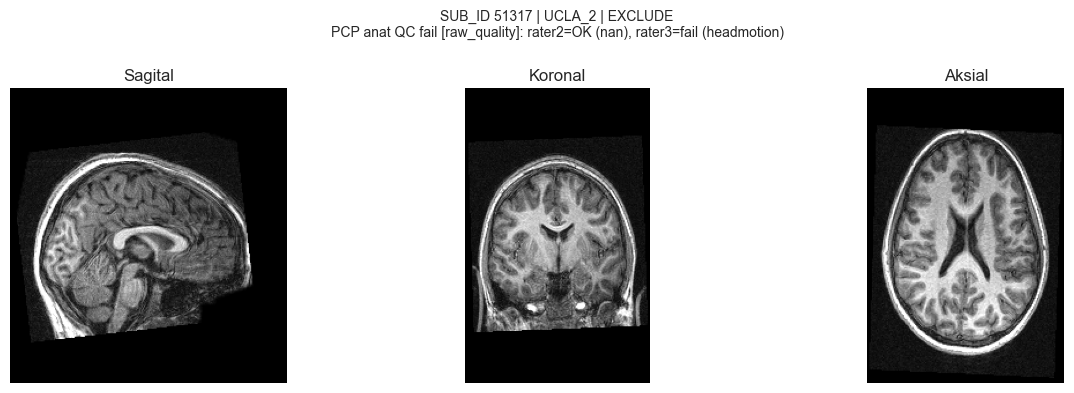

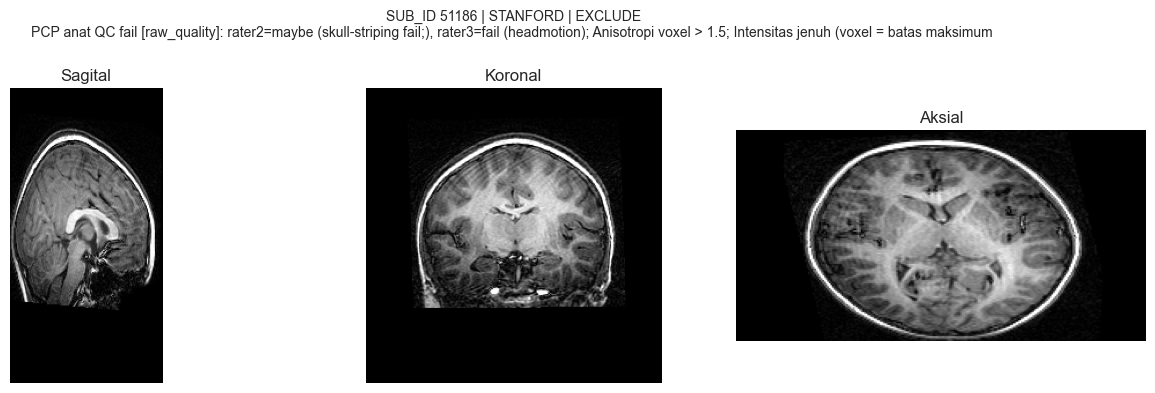

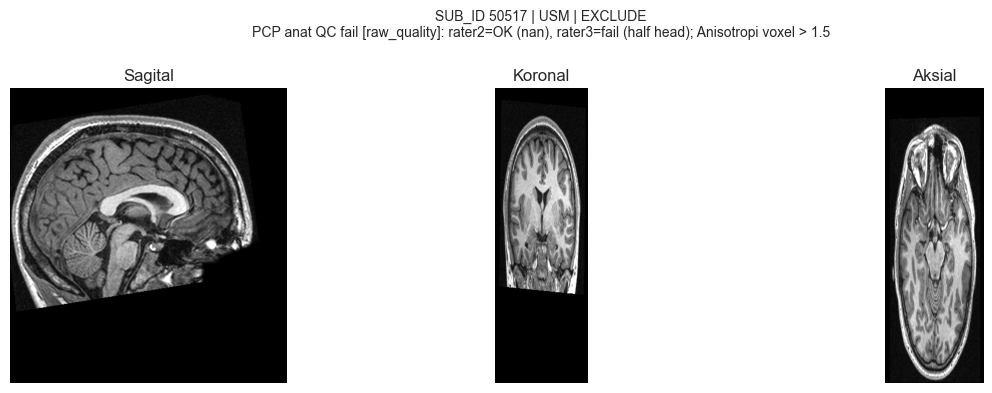

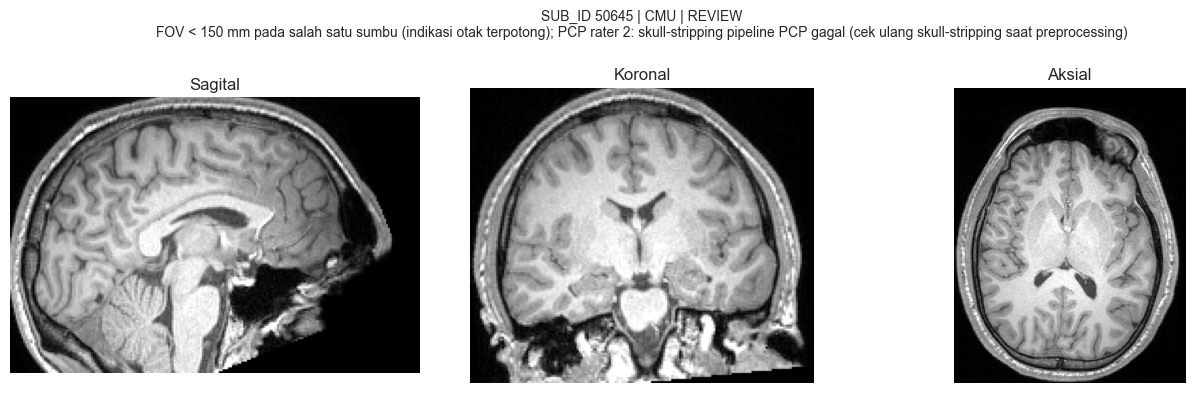

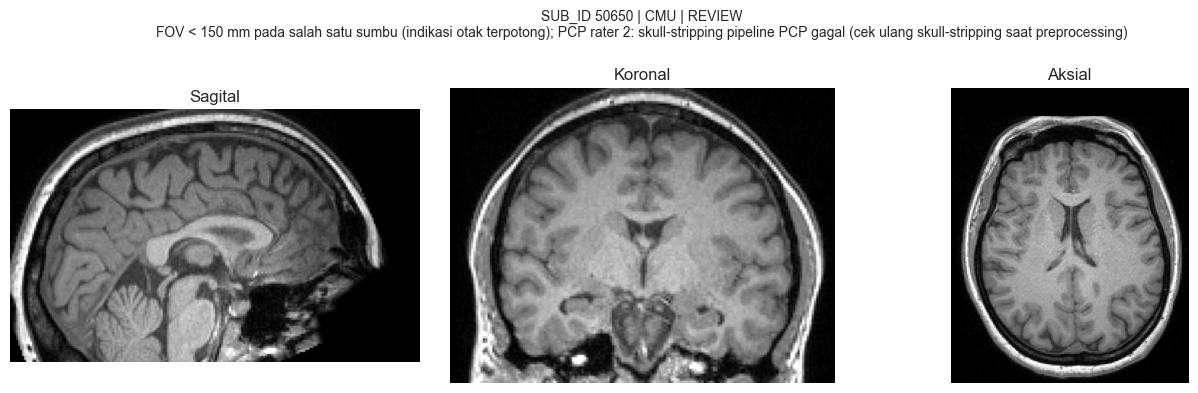

In [42]:
def show_three_views(relative_path, title, percentile_clip=(1, 99)):
    data = np.asarray(nib.load(str(PROJECT_ROOT / relative_path)).get_fdata(dtype=np.float32))
    low, high = np.percentile(data[np.isfinite(data)], percentile_clip)
    clipped = np.clip(data, low, high)
    center = np.array(clipped.shape[:3]) // 2
    views = [(clipped[center[0], :, :], "Sagital"), (clipped[:, center[1], :], "Koronal"),
             (clipped[:, :, center[2]], "Aksial")]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for axis, (slice_data, label) in zip(axes, views):
        axis.imshow(np.rot90(slice_data), cmap="gray")
        axis.set_title(label)
        axis.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


if SHOW_QC_EXAMPLES:
    examples = pd.concat([
        smri_qc[smri_qc["qc_decision"] == "EXCLUDE"].sample(min(3, int((smri_qc["qc_decision"] == "EXCLUDE").sum())), random_state=42),
        smri_qc[smri_qc["flag_fov_lt_150mm"] & smri_qc["qc_decision"].eq("REVIEW")].head(2),
    ])
    for _, row in examples.iterrows():
        show_three_views(row["smri_path"], f"SUB_ID {row['SUB_ID']} | {row['SITE_ID']} | {row['qc_decision']}\n"
                                           f"{row['qc_reason'][:160]}")

### 6.6 Drop subjek yang gagal QC

Drop dilakukan bertahap (QC teknis dulu, lalu QC kualitas) supaya diagram retensi menunjukkan di tahap mana setiap subjek gugur. Subjek `REVIEW` dicatat sebagai `FLAGGED`.

In [43]:
qc_lookup = smri_qc.set_index("SUB_ID")

technical_fail_ids = smri_qc.loc[smri_qc["qc_hard_fail"], "SUB_ID"]
log_event(technical_fail_ids, "04_smri_qc_technical", "DROPPED",
          list(qc_lookup.loc[technical_fail_ids, "qc_reason"]))
df_selected = df_selected[~df_selected["SUB_ID"].isin(technical_fail_ids)]
record_retention("2. Lolos QC teknis citra", df_selected["SUB_ID"])

quality_fail_ids = smri_qc.loc[~smri_qc["qc_hard_fail"] & smri_qc["qc_decision"].eq("EXCLUDE"), "SUB_ID"]
log_event(quality_fail_ids, "04_smri_qc_quality", "DROPPED",
          list(qc_lookup.loc[quality_fail_ids, "qc_reason"]))
df_selected = df_selected[~df_selected["SUB_ID"].isin(quality_fail_ids)]
stage_name = "3. Lolos QC kualitas (PCP" + (" + soft flag terpilih)" if DROP_ON_SOFT_FLAGS else ")")
record_retention(stage_name, df_selected["SUB_ID"])

review_ids = smri_qc.loc[smri_qc["qc_decision"].eq("REVIEW"), "SUB_ID"]
log_event(review_ids, "04_smri_qc_review", "FLAGGED", list(qc_lookup.loc[review_ids, "qc_reason"]))

print(f"Drop QC teknis  : {len(technical_fail_ids)}")
print(f"Drop QC kualitas: {len(quality_fail_ids)}")
print(f"Ditandai REVIEW : {len(review_ids)}")
print(f"Sisa subjek     : {len(df_selected)}")

Drop QC teknis  : 0
Drop QC kualitas: 98
Ditandai REVIEW : 411
Sisa subjek     : 1004


## 7. Kelengkapan data esensial & kriteria inklusi

Subjek wajib memiliki `SUB_ID`, `SITE_ID`, `DX_GROUP`, `AGE_AT_SCAN`, `SEX`, dan `smri_path` yang valid. `FIQ` dan `HANDEDNESS_CATEGORY` **boleh kosong**. Keduanya diimputasi di tahap preprocessing, dengan imputer yang di-*fit* hanya pada data latih.

In [44]:
path_invalid = ~df_selected["smri_path"].map(lambda path: isinstance(path, str) and (PROJECT_ROOT / path).is_file())
missing_essential = df_selected[ESSENTIAL_COLUMNS].isna().any(axis=1) | path_invalid
essential_reasons = df_selected[ESSENTIAL_COLUMNS].isna().apply(
    lambda row: "Data esensial kosong: " + ", ".join(row.index[row]), axis=1)
essential_reasons[path_invalid] = "smri_path tidak valid"
log_event(df_selected.loc[missing_essential, "SUB_ID"], "05_inclusion", "DROPPED",
          list(essential_reasons[missing_essential]))
df_selected = df_selected[~missing_essential]

if INCLUDE_AGE_RANGE is not None:
    low, high = INCLUDE_AGE_RANGE
    outside_age = ~df_selected["AGE_AT_SCAN"].between(low, high)
    log_event(df_selected.loc[outside_age, "SUB_ID"], "05_inclusion", "DROPPED",
              f"Di luar kriteria inklusi usia {low}-{high} tahun")
    df_selected = df_selected[~outside_age]
    print(f"Drop kriteria usia {INCLUDE_AGE_RANGE}: {int(outside_age.sum())}")

record_retention("4. Data esensial lengkap & kriteria inklusi", df_selected["SUB_ID"])
print(f"Drop data esensial tidak lengkap: {int(missing_essential.sum())}")
print(f"Sisa subjek: {len(df_selected)}")

Drop data esensial tidak lengkap: 0
Sisa subjek: 1004


### 7.1 Keseimbangan kelas per site

Setiap site sebaiknya tetap memiliki kedua kelas dalam jumlah memadai. Ini penting untuk harmonisasi antar-site (misalnya ComBat) dan untuk split/cross-validation yang distratifikasi per site. Site dengan kelas di bawah `MIN_PER_CLASS_PER_SITE` hanya **diperingatkan**, tidak dibuang otomatis.

In [45]:
def site_class_table(frame):
    labels = frame["SUB_ID"].map(SUBJECT_INFO["DX_LABEL"])
    table = pd.crosstab(frame["SITE_ID"], labels).reindex(columns=["ASD", "TD"], fill_value=0)
    table["total"] = table.sum(axis=1)
    return table


site_before = site_class_table(df)
site_after = site_class_table(df_selected)
site_comparison = site_before.join(site_after, lsuffix="_awal", rsuffix="_akhir", how="left").fillna(0).astype(int)
site_comparison["dropped"] = site_comparison["total_awal"] - site_comparison["total_akhir"]
site_comparison["retensi_pct"] = (site_comparison["total_akhir"] / site_comparison["total_awal"] * 100).round(1)
site_comparison["min_class_akhir"] = site_comparison[["ASD_akhir", "TD_akhir"]].min(axis=1)
site_comparison = site_comparison.sort_values("total_akhir", ascending=False)
display(site_comparison)

weak_sites = site_comparison[site_comparison["min_class_akhir"] < MIN_PER_CLASS_PER_SITE]
if weak_sites.empty:
    print(f"Semua site memiliki >= {MIN_PER_CLASS_PER_SITE} subjek per kelas.")
else:
    print(f"PERINGATAN: site dengan < {MIN_PER_CLASS_PER_SITE} subjek pada salah satu kelas:")
    display(weak_sites[["ASD_akhir", "TD_akhir", "total_akhir"]])

SUB_ID,ASD_awal,TD_awal,total_awal,ASD_akhir,TD_akhir,total_akhir,dropped,retensi_pct,min_class_akhir
SITE_ID,,,,,,,,,
NYU,79,105,184,79,104,183,1,99.5,79
UM_1,55,55,110,37,54,91,19,82.7,37
USM,58,43,101,54,35,89,12,88.1,35
UCLA_1,41,32,73,37,28,65,8,89.0,28
PITT,30,27,57,29,27,56,1,98.2,27
YALE,28,28,56,26,27,53,3,94.6,26
MAX_MUN,24,33,57,20,32,52,5,91.2,20
TRINITY,24,25,49,21,25,46,3,93.9,21
KKI,22,33,55,16,27,43,12,78.2,16


Semua site memiliki >= 5 subjek per kelas.


## 8. Verifikasi & export

### 8.1 Diagram retensi subjek

,stage,n_subjects,n_ASD,n_TD,dropped_from_previous,retention_pct_from_start
0,0. Fenotipik ABIDE I,1112,539,573,0,100.0
1,1. Memiliki citra sMRI (master),1102,531,571,10,99.1
2,2. Lolos QC teknis citra,1102,531,571,0,99.1
3,3. Lolos QC kualitas (PCP),1004,469,535,98,90.3
4,4. Data esensial lengkap & kriteria inklusi,1004,469,535,0,90.3


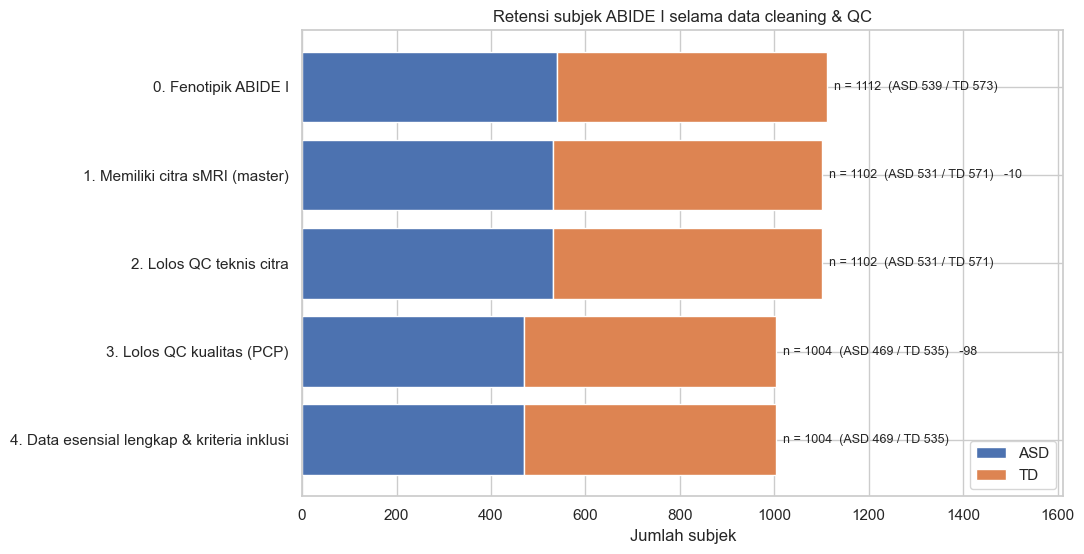

In [46]:
retention = pd.DataFrame(retention_records)
retention["dropped_from_previous"] = (-retention["n_subjects"].diff()).fillna(0).astype(int)
retention["retention_pct_from_start"] = (retention["n_subjects"] / retention["n_subjects"].iloc[0] * 100).round(1)
display(retention)

fig, ax = plt.subplots(figsize=(11, 0.9 * len(retention) + 1.2))
y_positions = np.arange(len(retention))[::-1]
ax.barh(y_positions, retention["n_ASD"], color="#4C72B0", label="ASD")
ax.barh(y_positions, retention["n_TD"], left=retention["n_ASD"], color="#DD8452", label="TD")
for y, (_, row) in zip(y_positions, retention.iterrows()):
    note = f"  n = {row['n_subjects']}  (ASD {row['n_ASD']} / TD {row['n_TD']})"
    if row["dropped_from_previous"]:
        note += f"   -{row['dropped_from_previous']}"
    ax.text(row["n_subjects"], y, note, va="center", fontsize=9)
ax.set_yticks(y_positions)
ax.set_yticklabels(retention["stage"])
ax.set_xlim(0, retention["n_subjects"].max() * 1.45)
ax.set_xlabel("Jumlah subjek")
ax.set_title("Retensi subjek ABIDE I selama data cleaning & QC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 8.2 Sebaran kelas ASD vs TD per SITE_ID (dataset final)

In [ ]:
fig, axes = plt.subplots(
    1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 2]}
)

# Tabel site setelah QC; pastikan kolom diagnosis selalu tersedia.
site_after_plot = (
    site_after
    .sort_values("total", ascending=False)
    .reindex(columns=["ASD", "TD"], fill_value=0)
)
site_after_plot.plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"]
)
axes[0].set_title("Dataset final: jumlah subjek per site")
axes[0].set_xlabel("SITE_ID")
axes[0].set_ylabel("Jumlah subjek")
axes[0].tick_params(axis="x", rotation=60)
axes[0].legend(title="Diagnosis")

# Samakan indeks dan kolom sebelum menghitung subjek yang di-drop.
site_after_aligned = (
    site_after
    .reindex(site_before.index, fill_value=0)
    .reindex(columns=["ASD", "TD"], fill_value=0)
)
dropped_by_site = (
    site_before[["ASD", "TD"]]
    .subtract(site_after_aligned[["ASD", "TD"]], fill_value=0)
    .clip(lower=0)
)
dropped_by_site = dropped_by_site.loc[
    dropped_by_site.sum(axis=1) > 0
].sort_values(["ASD", "TD"], ascending=False)

if dropped_by_site.empty:
    axes[1].text(0.5, 0.5, "Tidak ada subjek yang di-drop", ha="center", va="center")
    axes[1].set_axis_off()
else:
    dropped_by_site.plot(
        kind="barh", stacked=True, ax=axes[1],
        color=["#4C72B0", "#DD8452"]
    )
    axes[1].set_title("Subjek yang di-drop per site")
    axes[1].set_xlabel("Jumlah subjek")
    axes[1].set_ylabel("SITE_ID")
    axes[1].invert_yaxis()
    axes[1].legend(title="Diagnosis")

plt.tight_layout()
plt.show()

final_labels = df_selected["DX_GROUP"].map({1: "ASD", 0: "TD"})
final_distribution = (
    final_labels.value_counts()
    .reindex(["ASD", "TD"], fill_value=0)
    .to_frame("count")
)
final_distribution["percentage"] = (
    final_distribution["count"] / final_distribution["count"].sum() * 100
).round(2)
display(final_distribution)


### 8.3 Assert check

Notebook berhenti dengan error jika ada pemeriksaan yang gagal, sehingga output yang salah tidak sempat ditulis.

In [48]:
final_dataset = df_selected.reset_index(drop=True)
cleaning_log = pd.DataFrame(log_records, columns=[
    "step", "SUB_ID", "SITE_ID", "DX_LABEL", "action", "column", "old_value", "new_value", "reason"])
dropped_ids = set(cleaning_log.loc[cleaning_log["action"] == "DROPPED", "SUB_ID"])
final_paths_exist = final_dataset["smri_path"].map(lambda path: (PROJECT_ROOT / path).is_file())
special_left = int(final_dataset.isin(SPECIAL_MISSING_VALUES).sum().sum()
                   + final_dataset.astype(str).isin(["-9999", "-9999.0"]).sum().sum())

checks = {
    "Tidak ada SUB_ID ganda": final_dataset["SUB_ID"].is_unique,
    "Tidak ada nilai -9999 tersisa": special_left == 0,
    "Semua smri_path relatif & file ada": bool(final_paths_exist.all())
        and not final_dataset["smri_path"].str.contains(":", regex=False).any(),
    "Kolom sesuai KEEP_COLUMNS": list(final_dataset.columns) == KEEP_COLUMNS,
    "Kolom esensial tanpa NaN": bool(final_dataset[ESSENTIAL_COLUMNS].notna().all().all()),
    "DX_GROUP hanya {0, 1}": set(final_dataset["DX_GROUP"].unique()) <= {0, 1},
    "SEX hanya {1, 2}": set(final_dataset["SEX"].unique()) <= {1, 2},
    "FIQ_missing konsisten dengan FIQ": bool((final_dataset["FIQ_missing"] == final_dataset["FIQ"].isna().astype(int)).all()),
    "HANDEDNESS_CATEGORY hanya R/L/Ambi/NaN": set(final_dataset["HANDEDNESS_CATEGORY"].dropna()) <= {"R", "L", "Ambi"},
    "Tidak ada subjek EXCLUDE di dataset final": not final_dataset["SUB_ID"].isin(
        smri_qc.loc[smri_qc["qc_decision"] == "EXCLUDE", "SUB_ID"]).any(),
    "Subjek DROPPED tidak muncul di dataset final": dropped_ids.isdisjoint(final_dataset["SUB_ID"]),
    "Final + DROPPED = jumlah fenotipik awal": len(final_dataset) + len(dropped_ids) == len(phenotypic_raw),
    "smri_qc mencakup semua subjek master": len(smri_qc) == len(df_raw) and smri_qc["SUB_ID"].is_unique,
}
check_table = pd.DataFrame({"pemeriksaan": list(checks), "lulus": list(checks.values())})
display(check_table)
failed = check_table.loc[~check_table["lulus"], "pemeriksaan"].tolist()
assert not failed, f"Assert check gagal: {failed}"
print("Semua assert check lulus.")

,pemeriksaan,lulus
0,Tidak ada SUB_ID ganda,True
1,Tidak ada nilai -9999 tersisa,True
2,Semua smri_path relatif & file ada,True
3,Kolom sesuai KEEP_COLUMNS,True
4,Kolom esensial tanpa NaN,True
5,"DX_GROUP hanya {0, 1}",True
6,"SEX hanya {1, 2}",True
7,FIQ_missing konsisten dengan FIQ,True
8,HANDEDNESS_CATEGORY hanya R/L/Ambi/NaN,True
9,Tidak ada subjek EXCLUDE di dataset final,True


Semua assert check lulus.


### 8.4 Export output

- `cleaned_master_dataset.csv`: dataset final (9 kolom).
- `cleaning_log.csv`: log `DROPPED` / `FLAGGED` / `MODIFIED` per subjek beserta alasannya.
- `smri_qc.csv`: metrik header & intensitas, flag otomatis, rating & metrik QAP PCP, serta keputusan QC untuk **semua** 1.102 citra.
- `data_dictionary.csv`: arti dan encoding setiap kolom dataset final.

In [49]:
smri_qc["included_in_final"] = smri_qc["SUB_ID"].isin(final_dataset["SUB_ID"])
smri_qc["DX_LABEL"] = smri_qc["SUB_ID"].map(SUBJECT_INFO["DX_LABEL"])
qc_front = ["SUB_ID", "SITE_ID", "DX_LABEL", "smri_path", "qc_decision", "qc_reason", "included_in_final",
            "pcp_status", "qc_anat_rater_2", "qc_anat_notes_rater_2", "qc_anat_rater_3", "qc_anat_notes_rater_3"]
smri_qc_export = smri_qc[qc_front + [column for column in smri_qc.columns if column not in qc_front]]

step_order = {step: index for index, step in enumerate(cleaning_log["step"].unique())}
cleaning_log = cleaning_log.sort_values(["step", "action", "SUB_ID"],
                                        key=lambda column: column.map(step_order) if column.name == "step" else column)

data_dictionary = pd.DataFrame([
    ("SUB_ID", "ID subjek ABIDE I", "integer unik"),
    ("SITE_ID", "Site akuisisi", "20 kategori; untuk harmonisasi antar-site & stratified split"),
    ("DX_GROUP", "Label diagnosis (target)", "1 = ASD, 0 = TD (kode asli ABIDE: 1 = ASD, 2 = TD)"),
    ("AGE_AT_SCAN", "Usia saat pemindaian", f"tahun; rentang valid {AGE_VALID_RANGE}"),
    ("SEX", "Jenis kelamin", "1 = Laki-laki, 2 = Perempuan"),
    ("FIQ", "Full-scale IQ", f"rentang valid {FIQ_VALID_RANGE}; NaN = tidak tersedia (imputasi saat preprocessing, fit pada data latih)"),
    ("HANDEDNESS_CATEGORY", "Dominansi tangan", f"R / L / Ambi; sebagian diturunkan dari Edinburgh LQ (cutoff +/-{HANDEDNESS_SCORE_CUTOFF}); NaN = tidak tersedia"),
    ("FIQ_missing", "Indikator FIQ kosong", "1 = FIQ asli kosong/invalid, 0 = terisi"),
    ("smri_path", "Path citra T1w (.nii.gz)", "relatif terhadap PROJECT_ROOT, pemisah '/'"),
], columns=["column", "description", "encoding"])
data_dictionary["dtype"] = data_dictionary["column"].map(final_dataset.dtypes.astype(str))
data_dictionary["n_missing"] = data_dictionary["column"].map(final_dataset.isna().sum())
data_dictionary["missing_pct"] = (data_dictionary["n_missing"] / len(final_dataset) * 100).round(2)

final_dataset.to_csv(CLEANED_PATH, index=False)
cleaning_log.to_csv(LOG_PATH, index=False)
smri_qc_export.to_csv(QC_PATH, index=False)
data_dictionary.to_csv(DICTIONARY_PATH, index=False)
for path in [CLEANED_PATH, LOG_PATH, QC_PATH, DICTIONARY_PATH]:
    print(f"Tersimpan: {path}  ({path.stat().st_size / 1024:.1f} KB)")

display(data_dictionary)
display(cleaning_log.groupby(["step", "action"]).agg(n_rows=("SUB_ID", "size"), n_subjects=("SUB_ID", "nunique")))

Tersimpan: C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\cleaned_dataset\cleaned_master_dataset.csv  (74.5 KB)
Tersimpan: C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\cleaned_dataset\cleaning_log.csv  (110.9 KB)
Tersimpan: C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\cleaned_dataset\smri_qc.csv  (533.0 KB)
Tersimpan: C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\cleaned_dataset\data_dictionary.csv  (0.9 KB)


,column,description,encoding,dtype,n_missing,missing_pct
0,SUB_ID,ID subjek ABIDE I,integer unik,int64,0,0.00
1,SITE_ID,Site akuisisi,20 kategori; untuk harmonisasi antar-site & stratified split,object,0,0.00
2,DX_GROUP,Label diagnosis (target),"1 = ASD, 0 = TD (kode asli ABIDE: 1 = ASD, 2 = TD)",Int64,0,0.00
3,AGE_AT_SCAN,Usia saat pemindaian,"tahun; rentang valid (5, 70)",float64,0,0.00
4,SEX,Jenis kelamin,"1 = Laki-laki, 2 = Perempuan",Int64,0,0.00
5,FIQ,Full-scale IQ,"rentang valid (40, 160); NaN = tidak tersedia (imputasi saat preprocessing, fit pada data latih)",float64,71,7.07
6,HANDEDNESS_CATEGORY,Dominansi tangan,R / L / Ambi; sebagian diturunkan dari Edinburgh LQ (cutoff +/-40); NaN = tidak tersedia,object,14,1.39
7,FIQ_missing,Indikator FIQ kosong,"1 = FIQ asli kosong/invalid, 0 = terisi",int64,0,0.00
8,smri_path,Path citra T1w (.nii.gz),"relatif terhadap PROJECT_ROOT, pemisah '/'",object,0,0.00


n_rows  n_subjects
step               action                      
01_merge           DROPPED       10          10
02_phenotypic      FLAGGED       39          39
                   MODIFIED     363         339
04_smri_qc_quality DROPPED       98          98
04_smri_qc_review  FLAGGED      411         411

## 9. Ringkasan

In [50]:
final_counts = final_dataset["DX_GROUP"].value_counts()
print("=" * 72)
print("RINGKASAN DATA CLEANING & QC ABIDE I")
print("=" * 72)
for _, row in retention.iterrows():
    print(f"{row['stage']:<48} n = {row['n_subjects']:>4}  (ASD {row['n_ASD']:>3} / TD {row['n_TD']:>3})")
print(f"\nDataset final : {final_dataset.shape[0]} subjek x {final_dataset.shape[1]} kolom, {final_dataset['SITE_ID'].nunique()} site")
print(f"Kelas         : ASD = {final_counts.get(1, 0)}, TD = {final_counts.get(0, 0)}")
print(f"FIQ kosong    : {int(final_dataset['FIQ_missing'].sum())} subjek (diimputasi saat preprocessing)")
print(f"Handedness kosong : {int(final_dataset['HANDEDNESS_CATEGORY'].isna().sum())} subjek")
print(f"Citra REVIEW di dataset final: {int(smri_qc.loc[smri_qc['included_in_final'], 'qc_decision'].eq('REVIEW').sum())}")
print(f"Aturan fail PCP: {PCP_FAIL_RULE} | soft flag yang men-drop: {DROP_ON_SOFT_FLAGS or 'tidak ada'}")
print("\nCatatan untuk tahap Preprocessing:")
print("- Baca citra dengan PROJECT_ROOT / smri_path.")
print("- Imputasi FIQ/HANDEDNESS dan scaling di-fit hanya pada data latih (hindari leakage).")
print("- Shape & voxel spacing masih heterogen antar-site -> resampling ke grid seragam + registrasi ke template.")
print("- Cek visual hasil skull-stripping/registrasi untuk citra REVIEW (lihat smri_qc.csv).")
print("- Pertimbangkan harmonisasi efek site (mis. ComBat) dan split yang distratifikasi per site.")

RINGKASAN DATA CLEANING & QC ABIDE I
0. Fenotipik ABIDE I                             n = 1112  (ASD 539 / TD 573)
1. Memiliki citra sMRI (master)                  n = 1102  (ASD 531 / TD 571)
2. Lolos QC teknis citra                         n = 1102  (ASD 531 / TD 571)
3. Lolos QC kualitas (PCP)                       n = 1004  (ASD 469 / TD 535)
4. Data esensial lengkap & kriteria inklusi      n = 1004  (ASD 469 / TD 535)

Dataset final : 1004 subjek x 9 kolom, 20 site
Kelas         : ASD = 469, TD = 535
FIQ kosong    : 71 subjek (diimputasi saat preprocessing)
Handedness kosong : 14 subjek
Citra REVIEW di dataset final: 411
Aturan fail PCP: raw_quality | soft flag yang men-drop: tidak ada

Catatan untuk tahap Preprocessing:
- Baca citra dengan PROJECT_ROOT / smri_path.
- Imputasi FIQ/HANDEDNESS dan scaling di-fit hanya pada data latih (hindari leakage).
- Shape & voxel spacing masih heterogen antar-site -> resampling ke grid seragam + registrasi ke template.
- Cek visual hasil skull-

## 10. Audit keputusan PASS / REVIEW / EXCLUDE

Bagian ini memeriksa kembali alasan eksklusi, penyebab status `REVIEW`, kesesuaian flag dengan citra anatomi T1-weighted, dan konsistensi retensi kelas. Status `REVIEW` tidak otomatis berarti dibuang atau aman; citra tersebut tetap dipertahankan dengan catatan untuk pemeriksaan visual dan preprocessing.

**Keputusan metodologis:** `EXCLUDE` hanya digunakan untuk hard failure atau kegagalan kualitas PCP sesuai `PCP_FAIL_RULE`. Soft flag teknis tidak otomatis menyebabkan eksklusi karena dapat merepresentasikan perbedaan protokol antar-site.


In [51]:
# Ringkasan alasan EXCLUDE: setiap EXCLUDE harus memiliki minimal satu alasan eksplisit.
exclude_rows = smri_qc.loc[smri_qc["qc_decision"].eq("EXCLUDE")].copy()
exclude_reason_summary = pd.DataFrame({
    "reason_type": ["hard_flag", "PCP_anat_fail", "selected_soft_flag"],
    "n_subjects": [
        int(exclude_rows[HARD_QC_FLAGS].any(axis=1).sum()),
        int(exclude_rows["pcp_anat_fail"].sum()),
        int(exclude_rows[DROP_ON_SOFT_FLAGS].any(axis=1).sum()) if DROP_ON_SOFT_FLAGS else 0,
    ],
})
display(exclude_reason_summary)
print(f"Total EXCLUDE: {len(exclude_rows)}")
print("Kesimpulan: alasan EXCLUDE harus ditelusuri pada kolom qc_reason dan cleaning_log.")
if not exclude_rows.empty:
    display(exclude_rows[["SUB_ID", "SITE_ID", "qc_decision", "qc_reason"]].head(20))
assert exclude_rows["qc_reason"].fillna("").str.len().gt(0).all(), "Ada EXCLUDE tanpa alasan eksplisit."


,reason_type,n_subjects
0,hard_flag,0
1,PCP_anat_fail,98
2,selected_soft_flag,0


Total EXCLUDE: 98
Kesimpulan: alasan EXCLUDE harus ditelusuri pada kolom qc_reason dan cleaning_log.


,SUB_ID,SITE_ID,qc_decision,qc_reason
72,50779,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (quality check)"
77,50784,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (less headmotion)"
78,50785,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (headmotion)"
80,50787,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (less headmotion)"
81,50788,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (less headmotion)"
82,50789,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (headmotion)"
87,50794,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (headmotion)"
88,50795,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (headmotion)"
99,50806,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=OK (nan), rater3=fail (headmotion)"
108,50815,KKI,EXCLUDE,"PCP anat QC fail [raw_quality]: rater2=maybe (motion), rater3=fail (headmotion); Rating PCP = maybe"


In [54]:
# Penyebab REVIEW ditampilkan sebagai flag, bukan sebagai keputusan drop otomatis.
review_rows = smri_qc.loc[smri_qc["qc_decision"].eq("REVIEW")].copy()

# Gabungkan daftar flag yang ingin dianalisis
review_flags = SOFT_QC_FLAGS + ["flag_pcp_skullstrip_fail", "flag_pcp_maybe"]

# Hitung jumlah kejadian tiap flag secara efisien
review_reason_summary = (
    review_rows[review_flags]
    .sum()
    .astype(int)
    .to_frame(name="n_review")
    .sort_values("n_review", ascending=False)
)

display(review_reason_summary)
print(f"Total REVIEW: {len(review_rows)}")
print("Tindak lanjut: pemeriksaan visual dan evaluasi hasil preprocessing; jangan drop otomatis hanya karena REVIEW.")

,n_review
flag_pcp_maybe,148
flag_fov_lt_150mm,122
flag_anisotropy_gt_1_5,116
flag_sform_code_0,96
flag_negative_intensity,36
flag_pcp_skullstrip_fail,35
flag_intensity_saturated,24
flag_voxel_gt_1_5mm,0


Total REVIEW: 411
Tindak lanjut: pemeriksaan visual dan evaluasi hasil preprocessing; jangan drop otomatis hanya karena REVIEW.


### Interpretasi QC untuk citra anatomi T1-weighted

| Jenis pemeriksaan | Keputusan | Alasan metodologis |
|---|---|---|
| File corrupt, gagal dibaca, bukan 3D, volume kosong, NaN/Inf, ID mismatch | `EXCLUDE` | Informasi citra tidak dapat digunakan secara reliabel |
| Motion/noise/half-head berat pada rating PCP | `EXCLUDE` | Masalah kualitas citra mentah tidak dapat dipulihkan dengan preprocessing biasa |
| FOV kecil, anisotropi, voxel spacing, sform, intensitas | `REVIEW` | Dapat terkait protokol site dan perlu diperiksa bersama hasil reorientasi/resampling |
| Rating PCP `maybe` atau skull-strip PCP gagal | `REVIEW` | Pipeline PCP berbeda dari pipeline penelitian; perlu verifikasi visual dan preprocessing sendiri |

Dengan demikian, QC Notebook 04 menentukan **kelayakan awal**, sedangkan perbaikan teknis citra dilakukan pada Notebook 05. Jika pemeriksaan visual/preprocessing membuktikan citra `REVIEW` tidak layak, keputusan tersebut harus dicatat dan dataset final dibentuk ulang secara eksplisit, bukan dihapus diam-diam.

In [55]:
# Konsistensi retensi dan distribusi kelas setelah QC.
qc_class_check = final_dataset["DX_GROUP"].value_counts().rename_axis("DX_GROUP").to_frame("count")
qc_class_check["label"] = qc_class_check.index.map({1: "ASD", 0: "TD"})
qc_class_check["percentage"] = qc_class_check["count"] / len(final_dataset) * 100
display(qc_class_check)
print(f"Retensi dari master: {len(final_dataset)}/{len(df)} = {len(final_dataset) / len(df) * 100:.1f}%")
print(f"Final: ASD={int((final_dataset["DX_GROUP"] == 1).sum())}, TD={int((final_dataset["DX_GROUP"] == 0).sum())}")
assert len(exclude_rows) == 98, "Jumlah EXCLUDE berubah; tinjau ulang output QC dan aturan PCP."
assert len(review_rows) == 411, "Jumlah REVIEW berubah; tinjau ulang flag QC."
assert len(final_dataset) == 1004, "Jumlah dataset final berubah; tinjau ulang retensi."
assert set(final_dataset["DX_GROUP"].unique()) <= {0, 1}
print("Audit QC final lulus: jumlah EXCLUDE, REVIEW, retensi, dan label konsisten dengan output saat ini.")


,count,label,percentage
DX_GROUP,,,
0,535,TD,53.286853
1,469,ASD,46.713147


Retensi dari master: 1004/1102 = 91.1%
Final: ASD=469, TD=535
Audit QC final lulus: jumlah EXCLUDE, REVIEW, retensi, dan label konsisten dengan output saat ini.
